In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import json

from pathlib import Path

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

DATA_PATH = Path("../data/raw/paysim.parquet")
OUTPUT_PATH = Path("../data/processed")

df = pd.read_parquet(
    DATA_PATH,
    columns=[
        "step",
        "type",
        "amount",
        "nameDest",
        "isFraud",
        "isFlaggedFraud"
    ]
)

df = df.astype({
    "step": "int16",
    "type": "category",
    "nameDest": "category",
    "isFraud": "int8",
    "isFlaggedFraud": "int8"
})

df.head()

,step,type,amount,nameDest,isFraud,isFlaggedFraud
0,1,PAYMENT,9839.64,M1979787155,0,0
1,1,PAYMENT,1864.28,M2044282225,0,0
2,1,TRANSFER,181.00,C553264065,1,0
3,1,CASH_OUT,181.00,C38997010,1,0
4,1,PAYMENT,11668.14,M1230701703,0,0


## Feature Engineering Strategy

The objective of this notebook is to develop meaningful predictive
features while preventing target and temporal data leakage.

Based on the exploratory data analysis, feature engineering will
focus on:

- Transaction characteristics
- Transaction amount transformations
- Temporal transaction patterns
- Recipient account characteristics
- Historical recipient behavior

All historical features will be constructed using transactions
from strictly earlier simulation hours.

Account balance variables and the existing fraud flag will not
be used as predictive features due to potential data leakage.

The existing fraud flag will be retained exclusively for
benchmark evaluation.

In [2]:
min_step = df["step"].min()
max_step = df["step"].max()

duration = max_step - min_step + 1

train_end = min_step + int(duration * 0.60) - 1
val_end = min_step + int(duration * 0.80) - 1

df["split"] = np.select(
    [
        df["step"] <= train_end,
        df["step"] <= val_end
    ],
    [
        "train",
        "validation"
    ],
    default="test"
)

df["split"].value_counts()

split
train         6010937
validation     228103
test           123580
Name: count, dtype: int64

In [3]:
split_summary = df.groupby("split").agg(
    start_step=("step", "min"),
    end_step=("step", "max"),
    total_transactions=("isFraud", "count"),
    fraudulent_transactions=("isFraud", "sum")
)

split_summary["fraud_rate"] = (
    split_summary["fraudulent_transactions"] /
    split_summary["total_transactions"] * 100
)

split_summary.loc[["train", "validation", "test"]]

,start_step,end_step,total_transactions,fraudulent_transactions,fraud_rate
split,,,,,
train,1,445,6010937,5007,0.083298
validation,446,594,228103,1552,0.680394
test,595,743,123580,1654,1.338404


In [4]:
df["log_amount"] = np.log1p(df["amount"])

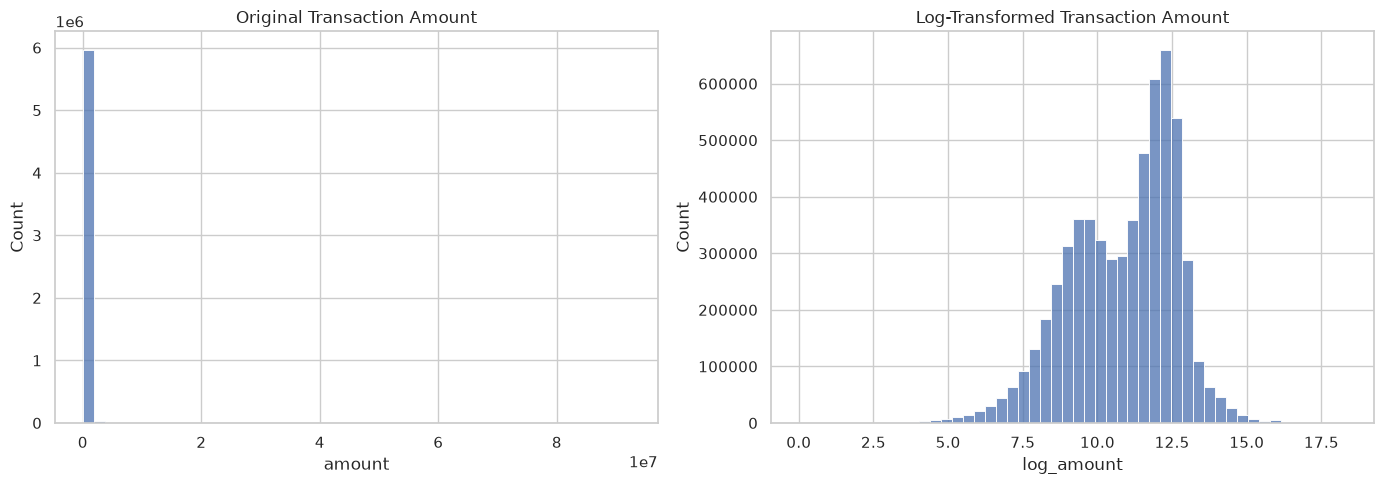

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

train_mask = df["split"] == "train"

sns.histplot(
    data=df.loc[train_mask],
    x="amount",
    bins=50,
    ax=axes[0]
)

axes[0].set_title("Original Transaction Amount")

sns.histplot(
    data=df.loc[train_mask],
    x="log_amount",
    bins=50,
    ax=axes[1]
)

axes[1].set_title("Log-Transformed Transaction Amount")

plt.tight_layout()
plt.show()

In [6]:
df["type"].value_counts()

type
CASH_OUT    2237500
PAYMENT     2151495
CASH_IN     1399284
TRANSFER     532909
DEBIT         41432
Name: count, dtype: int64

In [7]:
df["recipient_is_merchant"] = (
    df["nameDest"].str.startswith("M").astype("int8")
)

df[["nameDest", "recipient_is_merchant"]].head()

,nameDest,recipient_is_merchant
0,M1979787155,1
1,M2044282225,1
2,C553264065,0
3,C38997010,0
4,M1230701703,1


In [8]:
df["hour_of_day"] = (df["step"] - 1) % 24

df[["step", "hour_of_day"]].head()

,step,hour_of_day
0,1,0
1,1,0
2,1,0
3,1,0
4,1,0


In [9]:
df["hour_sin"] = np.sin(
    2 * np.pi * df["hour_of_day"] / 24
)

df["hour_cos"] = np.cos(
    2 * np.pi * df["hour_of_day"] / 24
)

In [10]:
def create_recipient_features(transactions):

    # Aggregate transactions by recipient and simulation hour
    history = (
        transactions.groupby(
            ["nameDest", "step"],
            sort=False,
            observed=True
        )
        .agg(
            hourly_count=("amount", "count"),
            hourly_total=("amount", "sum")
        )
        .reset_index()
        .sort_values(["nameDest", "step"])
        .reset_index(drop=True)
    )

    recipient_groups = history.groupby(
        "nameDest",
        sort=False,
        observed=True
    )

    # Number of transactions from strictly earlier hours
    history["recipient_prior_count"] = (
        recipient_groups["hourly_count"].cumsum()
        - history["hourly_count"]
    )

    # Total transaction amount from strictly earlier hours
    history["recipient_prior_total"] = (
        recipient_groups["hourly_total"].cumsum()
        - history["hourly_total"]
    )

    # Average historical transaction amount
    history["recipient_prior_mean"] = (
        history["recipient_prior_total"] /
        history["recipient_prior_count"].replace(0, np.nan)
    )

    # Time since the previous observed transaction hour
    history["recipient_hours_since_last"] = (
        history["step"] -
        recipient_groups["step"].shift(1)
    )

    # Identify recipients without historical activity
    history["recipient_is_new"] = (
        history["recipient_prior_count"] == 0
    ).astype("int8")

    history = history.drop(
        columns=["hourly_count", "hourly_total"]
    )

    # Attach historical features to original transactions
    result = transactions.merge(
        history,
        on=["nameDest", "step"],
        how="left",
        sort=False,
        validate="many_to_one"
    )

    # Compare the current transaction to historical behavior
    result["amount_to_recipient_mean"] = (
        result["amount"] /
        result["recipient_prior_mean"].replace(0, np.nan)
    )

    return result

In [11]:
test_df = pd.DataFrame({
    "nameDest": ["C1", "C1", "C1", "C1", "C2"],
    "step": [10, 12, 15, 15, 15],
    "amount": [200, 300, 500, 2000, 100]
})

test_result = create_recipient_features(test_df)

test_result

,nameDest,step,amount,recipient_prior_count,recipient_prior_total,recipient_prior_mean,recipient_hours_since_last,recipient_is_new,amount_to_recipient_mean
0,C1,10,200,0,0,NaN,NaN,1,NaN
1,C1,12,300,1,200,200.0,2.0,0,1.5
2,C1,15,500,2,500,250.0,3.0,0,2.0
3,C1,15,2000,2,500,250.0,3.0,0,8.0
4,C2,15,100,0,0,NaN,NaN,1,NaN


In [12]:
assert test_result["recipient_prior_count"].tolist() == [
    0, 1, 2, 2, 0
]

assert test_result["recipient_prior_total"].tolist() == [
    0, 200, 500, 500, 0
]

assert test_result.loc[2, "recipient_prior_mean"] == 250
assert test_result.loc[3, "recipient_prior_mean"] == 250

assert pd.isna(
    test_result.loc[0, "recipient_prior_mean"]
)

print("All temporal leakage tests passed.")

All temporal leakage tests passed.


In [13]:
original_rows = len(df)

df = create_recipient_features(df)

assert len(df) == original_rows

df.head()

,step,type,amount,nameDest,isFraud,isFlaggedFraud,split,log_amount,recipient_is_merchant,hour_of_day,hour_sin,hour_cos,recipient_prior_count,recipient_prior_total,recipient_prior_mean,recipient_hours_since_last,recipient_is_new,amount_to_recipient_mean
0,1,PAYMENT,9839.64,M1979787155,0,0,train,9.194276,1,0,0.0,1.0,0,0.0,NaN,NaN,1,NaN
1,1,PAYMENT,1864.28,M2044282225,0,0,train,7.531166,1,0,0.0,1.0,0,0.0,NaN,NaN,1,NaN
2,1,TRANSFER,181.00,C553264065,1,0,train,5.204007,0,0,0.0,1.0,0,0.0,NaN,NaN,1,NaN
3,1,CASH_OUT,181.00,C38997010,1,0,train,5.204007,0,0,0.0,1.0,0,0.0,NaN,NaN,1,NaN
4,1,PAYMENT,11668.14,M1230701703,0,0,train,9.364703,1,0,0.0,1.0,0,0.0,NaN,NaN,1,NaN


In [14]:
feature_summary = pd.DataFrame({
    "dtype": df.dtypes,
    "missing_count": df.isna().sum(),
    "missing_percentage": df.isna().mean() * 100,
    "unique_values": df.nunique()
})

feature_summary

,dtype,missing_count,missing_percentage,unique_values
step,int16,0,0.000000,743
type,category,0,0.000000,5
amount,float64,0,0.000000,5316900
nameDest,category,0,0.000000,2722362
isFraud,int8,0,0.000000,2
isFlaggedFraud,int8,0,0.000000,2
split,str,0,0.000000,3
log_amount,float64,0,0.000000,5316900
recipient_is_merchant,int8,0,0.000000,2
hour_of_day,int16,0,0.000000,24


In [15]:
train_df = df.loc[df["split"] == "train"]

print(
    "New recipients:",
    train_df["recipient_is_new"].mean()
)

print(
    "Transactions with recipient history:",
    1 - train_df["recipient_is_new"].mean()
)

New recipients: 0.4347125913979801
Transactions with recipient history: 0.5652874086020199


In [16]:
historical_features = [
    "recipient_prior_count",
    "recipient_prior_total",
    "recipient_prior_mean",
    "recipient_hours_since_last",
    "recipient_is_new",
    "amount_to_recipient_mean"
]

train_df.groupby("isFraud")[historical_features].mean().T

isFraud,0,1
recipient_prior_count,5.029192e+00,2.623327
recipient_prior_total,1.328020e+06,635593.931616
recipient_prior_mean,2.489369e+05,212548.759620
recipient_hours_since_last,2.341574e+01,34.100817
recipient_is_new,4.345469e-01,0.633513
amount_to_recipient_mean,2.586361e+00,20.835621


In [17]:
train_df.groupby("isFraud")[historical_features].median().T

isFraud,0,1
recipient_prior_count,1.000000,0.000000
recipient_prior_total,209534.280000,0.000000
recipient_prior_mean,201670.933021,182182.556250
recipient_hours_since_last,15.000000,22.000000
recipient_is_new,0.000000,1.000000
amount_to_recipient_mean,0.790043,2.495673


In [18]:
recipient_summary = train_df.groupby(
    "recipient_is_new"
).agg(
    total_transactions=("isFraud", "count"),
    fraudulent_transactions=("isFraud", "sum")
)

recipient_summary["fraud_rate"] = (
    recipient_summary["fraudulent_transactions"] /
    recipient_summary["total_transactions"] * 100
)

recipient_summary

,total_transactions,fraudulent_transactions,fraud_rate
recipient_is_new,,,
0,3397907,1835,0.054004
1,2613030,3172,0.121392


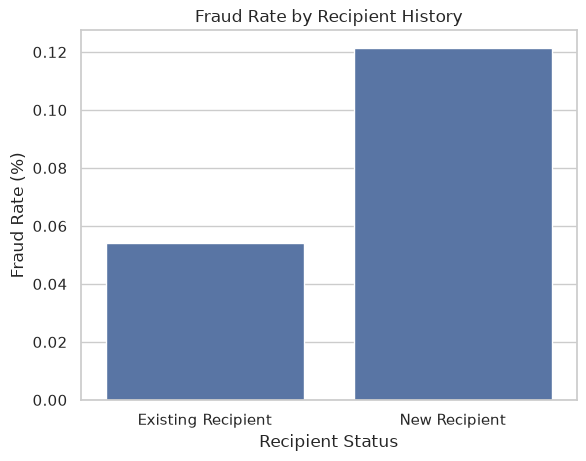

In [19]:
sns.barplot(
    data=recipient_summary.reset_index(),
    x="recipient_is_new",
    y="fraud_rate"
)

plt.xticks([0, 1], ["Existing Recipient", "New Recipient"])
plt.title("Fraud Rate by Recipient History")
plt.xlabel("Recipient Status")
plt.ylabel("Fraud Rate (%)")
plt.show()

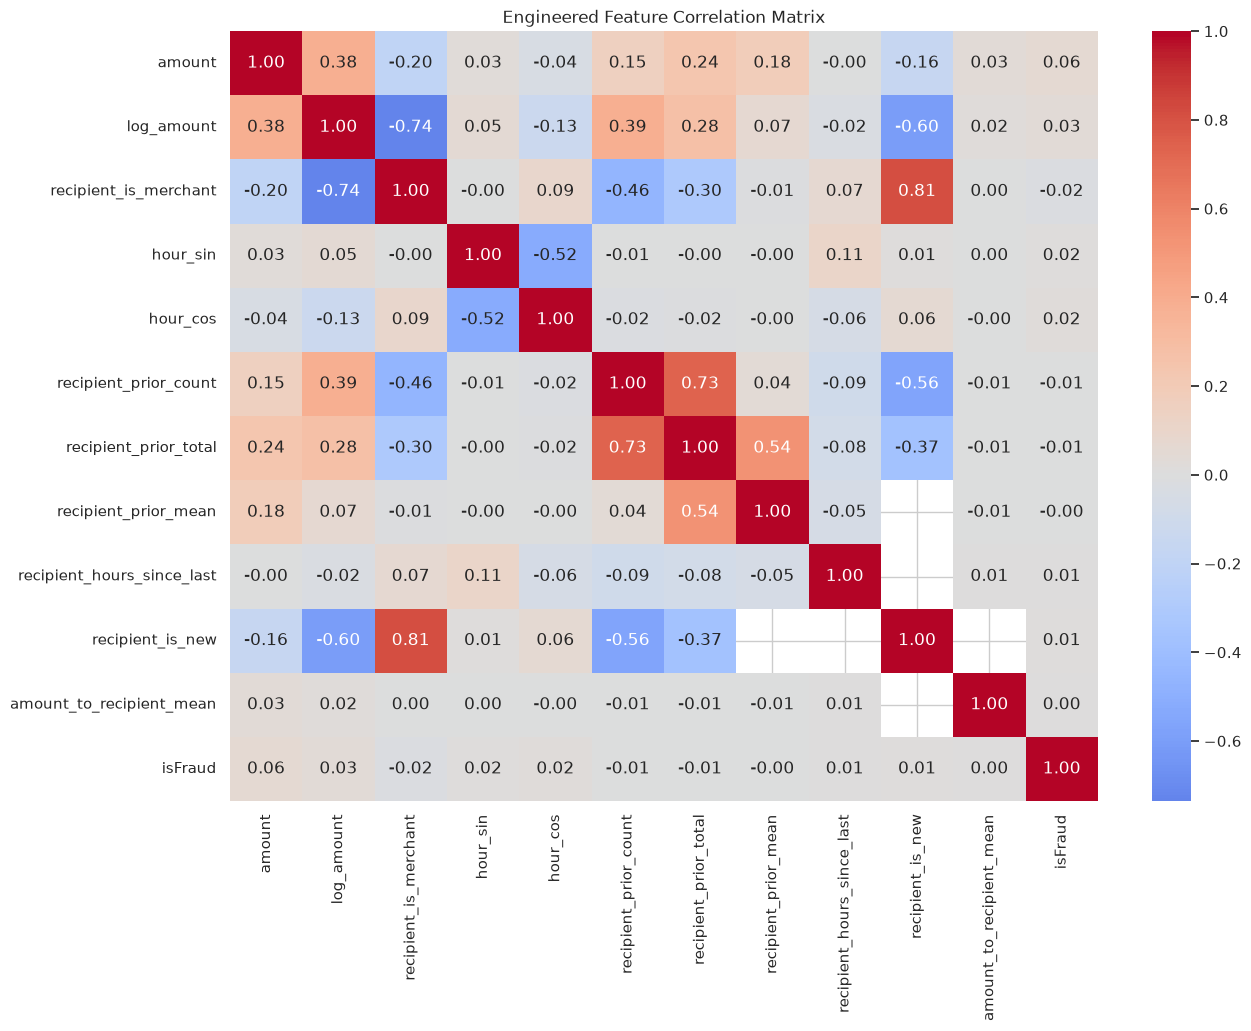

In [20]:
numeric_features = [
    "amount",
    "log_amount",
    "recipient_is_merchant",
    "hour_sin",
    "hour_cos",
    *historical_features,
    "isFraud"
]

plt.figure(figsize=(14, 10))

sns.heatmap(
    train_df[numeric_features].corr(),
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Engineered Feature Correlation Matrix")
plt.show()

In [21]:
transaction_features = [
    "type",
    "amount",
    "log_amount",
    "recipient_is_merchant"
]

temporal_features = [
    "hour_sin",
    "hour_cos"
]

behavioral_features = [
    "recipient_prior_count",
    "recipient_prior_total",
    "recipient_prior_mean",
    "recipient_hours_since_last",
    "recipient_is_new",
    "amount_to_recipient_mean"
]

feature_groups = {
    "transaction": transaction_features,
    "temporal": temporal_features,
    "behavioral": behavioral_features
}

feature_columns = (
    transaction_features
    + temporal_features
    + behavioral_features
)

target_column = "isFraud"

metadata_columns = [
    "step",
    "isFlaggedFraud"
]

print("Number of predictive features:", len(feature_columns))

Number of predictive features: 12


In [22]:
forbidden_features = {
    "oldbalanceOrg",
    "newbalanceOrig",
    "oldbalanceDest",
    "newbalanceDest",
    "isFlaggedFraud",
    "isFraud",
    "nameOrig",
    "nameDest",
    "step"
}

assert not forbidden_features.intersection(feature_columns)

assert df["recipient_prior_count"].ge(0).all()

assert df["recipient_prior_total"].ge(0).all()

assert df["recipient_hours_since_last"].dropna().gt(0).all()

assert (
    df["recipient_is_new"] ==
    (df["recipient_prior_count"] == 0).astype("int8")
).all()

assert not np.isinf(
    df[feature_columns].select_dtypes(include="number")
).any().any()

assert df.loc[df["split"] == "train", "step"].max() < \
       df.loc[df["split"] == "validation", "step"].min()

assert df.loc[df["split"] == "validation", "step"].max() < \
       df.loc[df["split"] == "test", "step"].min()

print("All feature validation checks passed.")

All feature validation checks passed.


In [23]:
export_columns = (
    feature_columns
    + metadata_columns
    + [target_column]
)

for split_name in ["train", "validation", "test"]:

    split_data = df.loc[
        df["split"] == split_name,
        export_columns
    ]

    output_file = OUTPUT_PATH / f"{split_name}.parquet"

    split_data.to_parquet(
        output_file,
        index=False
    )

    print(f"Saved {output_file}: {split_data.shape}")

Saved ../data/processed/train.parquet: (6010937, 15)
Saved ../data/processed/validation.parquet: (228103, 15)
Saved ../data/processed/test.parquet: (123580, 15)


In [24]:
metadata = {
    "feature_columns": feature_columns,
    "feature_groups": feature_groups,
    "target_column": target_column,
    "metadata_columns": metadata_columns,
    "train_end_step": int(train_end),
    "validation_end_step": int(val_end),
    "historical_feature_policy": "strictly earlier simulation hours"
}

with open(OUTPUT_PATH / "feature_metadata.json", "w") as f:
    json.dump(metadata, f, indent=4)

## Key Findings

### Transaction Features
- Created a logarithmic transformation of transaction amount to address the heavily right-skewed distribution identified during EDA.
- Retained both the original and log-transformed transaction amounts for model comparison.
- Preserved the five transaction types for categorical encoding during model preprocessing.
- Created a binary indicator distinguishing merchant and customer recipient accounts.

### Temporal Features
- Extracted the hour within each simulated day from the step variable.
- Applied sine and cosine transformations to preserve the cyclical nature of hourly transaction activity.
- Excluded the raw step variable from the primary predictive feature set to reduce dependence on simulation-specific temporal patterns.

### Historical Recipient Features
- Constructed six behavioral features capturing historical transaction frequency, cumulative transaction amounts, average transaction amounts, recency, recipient status, and relative transaction size.
- Fraudulent transactions are associated with recipients that have less historical activity.
- Legitimate transactions have an average recipient prior transaction count of 5.03, compared to 2.62 for fraudulent transactions.
- The median prior transaction count is 1 for legitimate transactions and 0 for fraudulent transactions.
- Recipients associated with fraudulent transactions have a longer average time since their previous observed transaction: 34.10 hours compared to 23.42 hours for legitimate transactions.
- Fraudulent transaction amounts are substantially larger relative to historical recipient averages.
- The median amount-to-recipient-mean ratio is 2.50 for fraudulent transactions compared to 0.79 for legitimate transactions.

### Historical Feature Coverage
- Approximately 56.53% of training transactions have available recipient transaction history.
- Approximately 43.47% of training transactions involve previously unseen recipients.
- Approximately 63.35% of fraudulent training transactions involve new recipients, compared to 43.45% of legitimate transactions.
- New recipients exhibit a fraud rate of 0.1214%, compared to 0.0540% for existing recipients.
- Transactions involving new recipients are approximately 2.25 times as likely to be fraudulent within the training dataset.
- Historical averages and recency features contain approximately 43.53% missing values across the full dataset because many recipients have no previously observed transaction history.
- Missing historical values represent meaningful information rather than data quality errors and will be handled during model preprocessing.

### Feature Relationships and Redundancy
- The engineered features capture complementary aspects of transaction characteristics, temporal activity, and recipient behavior.
- Some features, such as transaction amount and log-transformed amount, represent related information.
- Historical transaction count, cumulative amount, and average amount may also contain overlapping information.
- Feature ablation experiments will be conducted to quantify the incremental predictive value of each feature group.

### Temporal Data Splitting
- The dataset was partitioned chronologically using 60%, 20%, and 20% of the simulation duration.

| Dataset | Simulation Hours | Transactions | Fraudulent Transactions | Fraud Rate |
|---|---|---:|---:|---:|
| Training | 1–445 | 6,010,937 | 5,007 | 0.0833% |
| Validation | 446–594 | 228,103 | 1,552 | 0.6804% |
| Test | 595–743 | 123,580 | 1,654 | 1.3384% |

- Transaction volume is heavily concentrated within the training period.
- Fraud prevalence increases substantially across the chronological partitions.
- These differences indicate temporal distribution shift and changing class prevalence.
- Chronological splitting provides a more realistic evaluation of temporal generalization than random splitting.
- Although the entire dataset was descriptively examined during EDA, the test partition will not be used for model selection, hyperparameter tuning, or threshold optimization.

### Data Leakage Prevention
- All historical recipient features were calculated using transactions from strictly earlier simulation hours.
- Transactions occurring within the same simulation hour cannot contribute to each other's historical features.
- Historical feature construction does not use fraud labels.
- Account balance variables were excluded due to potential simulation-related target leakage.
- Raw account identifiers and the simulation step were excluded from the predictive feature set.
- The existing fraud flag was retained exclusively for benchmark evaluation.
- All implemented temporal leakage tests and feature validation assertions passed successfully.

### Final Feature Set
A total of 12 predictive features were created and organized into three feature groups:

**Transaction Features (4)**
- type
- amount
- log_amount
- recipient_is_merchant

**Temporal Features (2)**
- hour_sin
- hour_cos

**Behavioral Features (6)**
- recipient_prior_count
- recipient_prior_total
- recipient_prior_mean
- recipient_hours_since_last
- recipient_is_new
- amount_to_recipient_mean

### Data Export
- Successfully exported the training, validation, and test datasets in Parquet format.
- Each exported dataset contains 12 predictive features, two metadata columns, and one target variable.
- Preserved all 6,362,620 original transactions.
- Saved feature definitions, feature groups, chronological split boundaries, and historical feature policies in a JSON metadata file.
- Parquet storage improves data loading efficiency and eliminates the need to repeat feature engineering for every model experiment.

### Implications for Model Development
- Establish rule-based and logistic regression baselines.
- Investigate class weighting to address extreme class imbalance.
- Fit categorical encoding, scaling, and missing-value imputation exclusively on training data.
- Conduct feature ablation experiments to evaluate transaction, temporal, and behavioral feature contributions.
- Evaluate gradient-boosted tree models capable of capturing nonlinear feature relationships.
- Assess model robustness under temporal distribution shift.
- Evaluate probability calibration and cost-sensitive decision thresholds.
- Prioritize PR-AUC, precision, recall, F1-score, and fraudulent transaction value captured over classification accuracy.

## Conclusion

The feature engineering pipeline successfully transformed the raw PaySim dataset into a leakage-controlled, model-ready dataset containing 12 predictive features.

Historical recipient behavior demonstrates promising relationships with fraudulent activity, particularly recipient novelty, transaction recency, and transaction amounts relative to historical averages.

The chronological partitions reveal substantial temporal distribution shift, emphasizing the importance of robust model evaluation and generalization.

The next phase will focus on establishing baseline machine learning models, evaluating predictive performance, and quantifying the contribution of the engineered feature groups.